# Customer Churn Prediction

**Goal:** build and evaluate a classifier that flags customers at higher risk of churning, and explain *why* it flags them.

| Step | What happens |
|---|---|
| 1 | Audit and clean three raw tables (profile, account, usage), logging every decision |
| 2 | Engineer behavioural features; make one stratified train/test split |
| 3 | Compare logistic regression, decision tree and two ensembles (random forest, gradient boosting) with cross-validation |
| 4 | Evaluate with precision / recall / F1 / confusion matrices, tune the decision threshold, check class imbalance and data leakage |
| 5 | Explain predictions and analyse errors |

**Design rules used throughout**
* Cleaning here is *deterministic only* (fix labels, remove impossible values, drop duplicates). Anything that learns a statistic from data (imputation medians, winsorising limits, scaling, encoding) lives **inside the sklearn `Pipeline`** and is fit on training folds only.
* Model selection and threshold tuning use **cross-validation on the training set only**. The test set is touched once, at the end.
* Data is synthetic (`src/generate_data.py`) with realistic defects injected on purpose, so every cleaning step has something to do.

## 0. Setup

In [5]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, REP = ROOT / "data" / "raw", ROOT / "reports"
FIG = REP / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SNAPSHOT = pd.Timestamp("2026-06-30")   # end of the observation window; churn is observed after it

# Chart style: neutral ink, one blue/orange pair (retained = blue, churned = orange)
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.titlelocation": "left", "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 100,
})
BLUE_CMAP = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])


def style(ax, grid="y"):
    ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.tick_params(length=0)
    return ax


def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()


print("pandas", pd.__version__, "| numpy", np.__version__)
print("project root:", ROOT)

pandas 3.0.5 | numpy 2.5.2
project root: c:\Users\Windows10 Pro\Downloads


## 1. Load and audit the raw data

In [6]:
profile_raw = pd.read_csv(RAW / "customers_profile.csv")
accounts_raw = pd.read_csv(RAW / "customers_accounts.csv")
usage_raw = pd.read_csv(RAW / "customers_usage.csv")

audit = pd.DataFrame({
    "table": ["profile", "accounts", "usage"],
    "rows": [len(profile_raw), len(accounts_raw), len(usage_raw)],
    "unique customers": [d.customer_id.nunique() for d in (profile_raw, accounts_raw, usage_raw)],
    "exact duplicate rows": [int(d.duplicated().sum()) for d in (profile_raw, accounts_raw, usage_raw)],
    "duplicated customer_id": [int(d.customer_id.duplicated().sum()) for d in (profile_raw, accounts_raw)] + ["n/a (6 rows each)"],
})
audit

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\Windows10 Pro\\Downloads\\data\\raw\\customers_profile.csv'

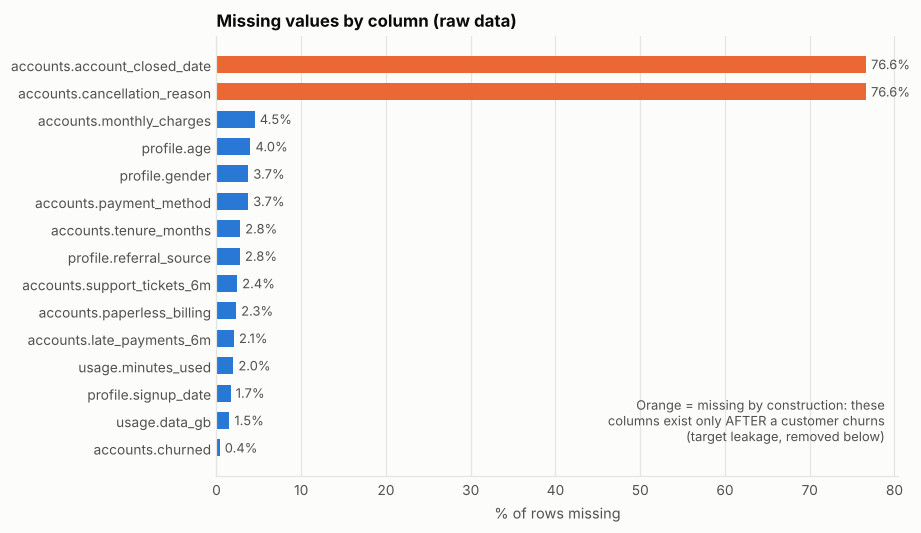

In [ ]:
miss = pd.concat([
    (d.isna().mean() * 100).rename("pct").rename_axis("column").reset_index().assign(table=t)
    for t, d in [("profile", profile_raw), ("accounts", accounts_raw), ("usage", usage_raw)]
])
miss = miss[(miss.pct > 0) & (miss.column != "customer_id")].sort_values("pct")
miss["label"] = miss.table + "." + miss.column
structural = miss.column.isin(["cancellation_reason", "account_closed_date"])

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(miss.label, miss.pct, color=np.where(structural, ORANGE, BLUE), height=0.62)
for y, (v, s) in enumerate(zip(miss.pct, structural)):
    ax.text(v + 0.6, y, f"{v:.1f}%", va="center", fontsize=8.5, color=INK2)
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values by column (raw data)")
ax.text(0.98, 0.08, "Orange = missing by construction: these\ncolumns exist only AFTER a customer churns\n(target leakage, removed below)",
        transform=ax.transAxes, ha="right", fontsize=8.5, color=INK2)
style(ax, "x")
save(fig, "01_missing_values.png")

## 1b. Cleaning, with a documented decision for every problem

Every decision is appended to `cleaning_log`, which is saved to `reports/cleaning_log.csv`.

| Problem | Treatment | Where |
|---|---|---|
| Duplicates | Exact duplicates dropped; duplicated `customer_id` keeps the *most complete* record | here |
| Inconsistent categories (`M`, `male `, `MALE`) | Trim, lower-case, map to one canonical label; fail loudly on any unmapped value | here |
| Impossible values (age 999, negative charges / usage) | Set to missing (not deleted) so the row is still usable | here |
| Missing values | Tenure re-derived from `signup_date` when possible; categoricals become `"Unknown"`; numerics are **median-imputed with a missing-indicator inside the pipeline** (train-fit only) | here + pipeline |
| Outliers (x10 charge typos, usage spikes) | Robust aggregation (medians) for usage; **winsorised at the train-fit 1st/99th percentile** inside the pipeline | features + pipeline |
| Rows with no label | Dropped (cannot train or evaluate on them) | here |
| Post-churn columns | Removed (leakage) | here |

In [ ]:
cleaning_log = []


def log(table, issue, treatment, rows, why):
    cleaning_log.append({"table": table, "issue": issue, "treatment": treatment,
                         "rows_affected": int(rows), "rationale": why})


def standardize(s, mapping):
    """Trim + lower-case, map to canonical labels. Raises if anything is left unmapped."""
    key = s.astype("object").where(s.notna()).map(lambda v: str(v).strip().lower() if pd.notna(v) else np.nan)
    out = key.map(mapping)
    bad = key.notna() & out.isna()
    assert not bad.any(), f"{s.name}: unmapped values {sorted(key[bad].unique())}"
    return out


def n_relabelled(raw, clean):
    return int((raw.notna() & (raw.astype("object") != clean.astype("object"))).sum())


# ------------------------------------------------------------------ PROFILE
profile = profile_raw.copy()

n = profile.duplicated().sum()
profile = profile.drop_duplicates()
assert profile.customer_id.is_unique
log("profile", "Exact duplicate rows", "Dropped, kept first occurrence", n,
    "Duplicates would be split across train and test and inflate scores")

g_raw = profile.gender
profile["gender"] = standardize(g_raw, {"m": "Male", "male": "Male", "f": "Female", "female": "Female", "other": "Other"})
log("profile", "Inconsistent gender labels (M / male / MALE ...)", "Mapped to Male / Female / Other", n_relabelled(g_raw, profile.gender),
    "One label per concept so one-hot columns are not fragmented")
n = profile.gender.isna().sum()
profile["gender"] = profile.gender.fillna("Unknown")
log("profile", "Missing gender", 'Filled with category "Unknown"', n, "Missingness may itself carry signal; avoids guessing")

r_raw = profile.region
profile["region"] = r_raw.str.strip().str.title()
log("profile", "Region casing / whitespace", "Stripped and title-cased", n_relabelled(r_raw, profile.region), "Same region spelled several ways")

n = profile.referral_source.isna().sum()
profile["referral_source"] = profile.referral_source.fillna("Unknown")
log("profile", "Missing referral_source", 'Filled with "Unknown"', n, "Categorical; keeps the row")

invalid_age = profile.age.notna() & ~profile.age.between(18, 100)
log("profile", "Impossible age (0, -1, 5, 150, 999)", "Set to missing (valid range 18-100)", invalid_age.sum(),
    "Cannot be real; row kept, value imputed in pipeline")
profile.loc[invalid_age, "age"] = np.nan
log("profile", "Missing age (incl. invalid above)", "Left as NaN -> median-impute + missing-indicator inside pipeline",
    profile.age.isna().sum(), "Imputing before the split would leak test-set statistics")

profile["signup_date"] = pd.to_datetime(profile.signup_date, errors="coerce")

# ------------------------------------------------------------------ ACCOUNTS
LEAK_COLS = ["cancellation_reason", "account_closed_date"]
acc = accounts_raw.copy()

core = [c for c in acc.columns if c not in LEAK_COLS + ["customer_id"]]
acc["_missing"] = acc[core].isna().sum(axis=1)
n = acc.customer_id.duplicated().sum()
acc = (acc.sort_values(["customer_id", "_missing"], kind="stable")
          .drop_duplicates("customer_id", keep="first").drop(columns="_missing"))
log("accounts", "Duplicated customer_id with conflicting values", "Kept the record with the fewest missing fields", n,
    "Duplicate IDs break the one-row-per-customer assumption and can leak across the split")

for col, mapping in {
    "plan_type": {"basic": "Basic", "standard": "Standard", "std": "Standard", "premium": "Premium", "prem": "Premium"},
    "contract_type": {"month-to-month": "Month-to-month", "month to month": "Month-to-month", "monthly": "Month-to-month",
                      "m2m": "Month-to-month", "one year": "One year", "1 year": "One year", "1-year": "One year",
                      "two year": "Two year", "2 year": "Two year", "2-year": "Two year"},
    "payment_method": {"credit card": "Credit Card", "cc": "Credit Card", "debit card": "Debit Card", "dc": "Debit Card",
                       "upi": "UPI", "net banking": "Net Banking", "netbanking": "Net Banking",
                       "auto-debit": "Auto-debit", "auto debit": "Auto-debit", "autodebit": "Auto-debit"},
}.items():
    raw = acc[col]
    acc[col] = standardize(raw, mapping)
    log("accounts", f"Inconsistent {col} labels", "Mapped to canonical labels", n_relabelled(raw, acc[col]),
        "Spelling variants of the same category")

n = acc.payment_method.isna().sum()
acc["payment_method"] = acc.payment_method.fillna("Unknown")
log("accounts", "Missing payment_method", 'Filled with "Unknown"', n, "Categorical")

raw = acc.paperless_billing
acc["paperless_billing"] = standardize(raw, {"yes": "Yes", "y": "Yes", "true": "Yes", "no": "No", "n": "No", "false": "No"})
log("accounts", "paperless_billing written as Yes/Y/TRUE/no/N/FALSE", "Mapped to 1 / 0",
    n_relabelled(raw, acc.paperless_billing), "Boolean stored inconsistently")
acc["paperless_billing"] = acc.paperless_billing.map({"Yes": 1.0, "No": 0.0})

raw = acc.churned
acc["churned"] = standardize(raw, {"yes": "Yes", "y": "Yes", "1": "Yes", "no": "No", "n": "No", "0": "No"})
log("accounts", "Target written as Yes/yes/Y/1/No/no/N/0", "Mapped to 1 / 0", n_relabelled(raw, acc.churned), "Target must be one clean binary column")
acc["churned"] = acc.churned.map({"Yes": 1.0, "No": 0.0})
n = acc.churned.isna().sum()
acc = acc[acc.churned.notna()].copy()
acc["churned"] = acc.churned.astype(int)
log("accounts", "Rows with no churn label", "Dropped", n, "Unlabelled rows cannot be used for training or scoring")

neg = acc.monthly_charges.notna() & (acc.monthly_charges <= 0)
log("accounts", "Non-positive monthly_charges", "Set to missing", neg.sum(), "Refunds/sign errors, not a real price")
acc.loc[neg, "monthly_charges"] = np.nan
q1, q3 = acc.monthly_charges.quantile([0.25, 0.75])
n_out = (acc.monthly_charges > q3 + 3 * (q3 - q1)).sum()
log("accounts", "Extreme monthly_charges (x10 entry errors)", "Kept; winsorised at train-fit 1st/99th percentile inside pipeline", n_out,
    "Flagged with the 3xIQR rule; capping is fit on training data only")
log("accounts", "Missing monthly_charges / counts / paperless", "Left as NaN -> median-impute + indicator inside pipeline",
    acc[["monthly_charges", "support_tickets_6m", "late_payments_6m", "paperless_billing"]].isna().any(axis=1).sum(),
    "Imputation statistics must come from training folds only")

# tenure: re-derive from signup_date where possible (deterministic, no learning)
acc = acc.merge(profile[["customer_id", "signup_date"]], on="customer_id", how="left")
derived = (SNAPSHOT.year - acc.signup_date.dt.year) * 12 + (SNAPSHOT.month - acc.signup_date.dt.month)
fill = acc.tenure_months.isna() & acc.signup_date.notna()
acc.loc[fill, "tenure_months"] = derived[fill]
log("accounts", "Missing tenure_months", "Re-derived from signup_date where available", fill.sum(),
    "Deterministic and exact, better than statistical imputation")

# leakage columns
leak = acc[["customer_id", "churned"] + LEAK_COLS].set_index("customer_id")
log("accounts", "cancellation_reason / account_closed_date", "Removed from modelling table", acc[LEAK_COLS[0]].notna().sum(),
    "Only populated after the customer has already churned = target leakage (audited in section 4)")
acc = acc.drop(columns=LEAK_COLS)

# ------------------------------------------------------------------ USAGE
use = usage_raw.copy()
n = use.duplicated().sum()
use = use.drop_duplicates()
assert not use.duplicated(["customer_id", "month"]).any()
log("usage", "Exact duplicate monthly rows", "Dropped", n, "Would double-count a month in averages")

for col in ["logins", "minutes_used", "data_gb", "features_used"]:
    bad = use[col].notna() & (use[col] < 0)
    if bad.any():
        log("usage", f"Negative {col}", "Set to missing", bad.sum(), "Usage cannot be negative")
        use.loc[bad, col] = np.nan
med = use.groupby("customer_id").minutes_used.transform("median")
log("usage", "Usage spikes (>5x the customer's own median minutes)", "Kept; handled by median-based aggregation + winsorising",
    (use.minutes_used / med > 5).sum(), "Robust statistics instead of deleting rows")
log("usage", "Missing months / missing values", "Features aggregate over observed months; months_observed kept as a feature",
    use[["minutes_used", "data_gb"]].isna().any(axis=1).sum() + (6 * use.customer_id.nunique() - len(use)),
    "Absence of usage is informative for churn")

print("clean shapes ->", "profile", profile.shape, "| accounts", acc.shape, "| usage", use.shape)

clean shapes -> profile (5000, 6) | accounts (4981, 11) | usage (28908, 6)


In [ ]:
cleaning_log_df = pd.DataFrame(cleaning_log)
cleaning_log_df.to_csv(REP / "cleaning_log.csv", index=False)
cleaning_log_df[["table", "issue", "treatment", "rows_affected"]]

,table,issue,treatment,rows_affected
0,profile,Exact duplicate rows,"Dropped, kept first occurrence",150
1,profile,Inconsistent gender labels (M / male / MALE ...),Mapped to Male / Female / Other,1684
2,profile,Missing gender,"Filled with category ""Unknown""",188
3,profile,Region casing / whitespace,Stripped and title-cased,1254
4,profile,Missing referral_source,"Filled with ""Unknown""",139
5,profile,"Impossible age (0, -1, 5, 150, 999)",Set to missing (valid range 18-100),8
6,profile,Missing age (incl. invalid above),Left as NaN -> median-impute + missing-indicat...,211
7,accounts,Duplicated customer_id with conflicting values,Kept the record with the fewest missing fields,60
8,accounts,Inconsistent plan_type labels,Mapped to canonical labels,1745
9,accounts,Inconsistent contract_type labels,Mapped to canonical labels,1693


## 2. Behavioural feature engineering and the train/test split

Usage is reshaped to one row per customer (6 monthly columns), then summarised into level, **trend**, **volatility** and **inactivity** features.
All features use *only that customer's own history inside the observation window*, so building them before the split cannot leak information between customers.

In [ ]:
def row_slope(a, min_obs=3):
    """OLS slope per row over the observed months (NaN-aware)."""
    x = np.arange(1, a.shape[1] + 1, dtype=float)[None, :]
    m = ~np.isnan(a)
    cnt = m.sum(1)
    with np.errstate(invalid="ignore", divide="ignore"):
        xm = (m * x).sum(1) / cnt
        ym = np.nansum(a, 1) / cnt
        dx = np.where(m, x - xm[:, None], 0.0)
        dy = np.where(m, a - ym[:, None], 0.0)
        slope = (dx * dy).sum(1) / (dx ** 2).sum(1)
    slope[cnt < min_obs] = np.nan
    return slope


def wide(col):
    return use.pivot(index="customer_id", columns="month", values=col).reindex(columns=range(1, 7))


L, M, G, F = wide("logins"), wide("minutes_used"), wide("data_gb"), wide("features_used")
uf = pd.DataFrame(index=L.index)
uf["avg_logins"] = L.mean(axis=1)
uf["avg_minutes"] = M.median(axis=1)                      # median = robust to the spikes
uf["avg_data_gb"] = G.median(axis=1)
uf["features_used_mean"] = F.mean(axis=1)
uf["logins_slope"] = row_slope(L.to_numpy())              # logins gained/lost per month
uf["logins_trend_pct"] = uf.logins_slope / (uf.avg_logins + 1)   # scale-free version of the trend
uf["logins_drop_ratio"] = (L.iloc[:, 4:].mean(axis=1) + 1) / (L.iloc[:, :2].mean(axis=1) + 1)  # last 2 vs first 2 months
uf["logins_cv"] = L.std(axis=1) / (L.mean(axis=1) + 1)    # volatility
uf["inactive_months"] = (L == 0).sum(axis=1).astype(float)
uf["months_observed"] = L.notna().sum(axis=1).astype(float)
uf["session_minutes"] = uf.avg_minutes / (uf.avg_logins + 1)

model_df = (acc.drop(columns="signup_date").set_index("customer_id")
               .join(profile.drop(columns="signup_date").set_index("customer_id"), how="left")
               .join(uf, how="left"))
model_df["months_observed"] = model_df.months_observed.fillna(0)
model_df["no_usage_record"] = (model_df.months_observed == 0).astype(float)
model_df["friction_score"] = model_df.support_tickets_6m + model_df.late_payments_6m
model_df["is_new_customer"] = (model_df.tenure_months <= 6).astype(float).where(model_df.tenure_months.notna())
model_df["minutes_per_dollar"] = model_df.avg_minutes / model_df.monthly_charges

CAT = ["gender", "region", "plan_type", "contract_type", "payment_method", "referral_source"]
CONT = ["age", "tenure_months", "monthly_charges", "avg_logins", "avg_minutes", "avg_data_gb", "features_used_mean",
        "logins_slope", "logins_trend_pct", "logins_drop_ratio", "logins_cv", "session_minutes", "minutes_per_dollar"]
DISC = ["support_tickets_6m", "late_payments_6m", "paperless_billing", "inactive_months", "months_observed",
        "is_new_customer", "friction_score", "no_usage_record"]
NUM = CONT + DISC
assert set(CAT + NUM + ["churned"]) == set(model_df.columns), set(model_df.columns) ^ set(CAT + NUM + ["churned"])

print(f"modelling table: {model_df.shape[0]:,} customers x {len(CAT) + len(NUM)} features")
print(f"customers with no usage history at all: {int(model_df.no_usage_record.sum())}")
engineered = pd.DataFrame({
    "feature": ["avg_logins / avg_minutes / avg_data_gb", "logins_slope, logins_trend_pct", "logins_drop_ratio", "logins_cv",
                "inactive_months, months_observed, no_usage_record", "session_minutes, minutes_per_dollar",
                "friction_score", "is_new_customer"],
    "idea": ["Typical engagement level (median for minutes / data = spike-robust)", "Is engagement rising or falling month to month?",
             "Last 2 months relative to first 2 months", "How erratic is usage?", "Silence / gaps in the usage record",
             "Depth of use, and value for money", "Support tickets + late payments", "Customers in their first 6 months"],
})
engineered

modelling table: 4,981 customers x 27 features
customers with no usage history at all: 40


,feature,idea
0,avg_logins / avg_minutes / avg_data_gb,Typical engagement level (median for minutes /...
1,"logins_slope, logins_trend_pct",Is engagement rising or falling month to month?
2,logins_drop_ratio,Last 2 months relative to first 2 months
3,logins_cv,How erratic is usage?
4,"inactive_months, months_observed, no_usage_record",Silence / gaps in the usage record
5,"session_minutes, minutes_per_dollar","Depth of use, and value for money"
6,friction_score,Support tickets + late payments
7,is_new_customer,Customers in their first 6 months


In [ ]:
X = model_df.drop(columns="churned")
y = model_df["churned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

assert X_train.index.is_unique and X_test.index.is_unique
assert len(set(X_train.index) & set(X_test.index)) == 0, "customer appears in both train and test"
split_summary = pd.DataFrame({
    "customers": [len(y_train), len(y_test)],
    "churners": [int(y_train.sum()), int(y_test.sum())],
    "churn rate": [y_train.mean(), y_test.mean()],
}, index=["train (80%)", "test (20%)"])
split_summary.round(3)

,customers,churners,churn rate
train (80%),3984,934,0.234
test (20%),997,234,0.235


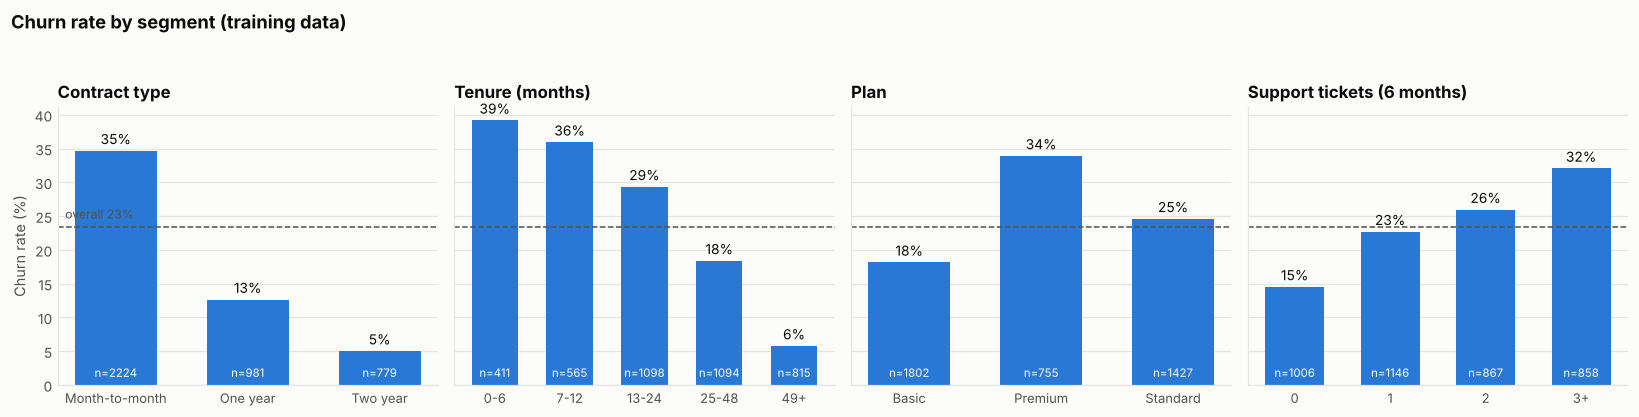

In [ ]:
# Exploratory charts use the TRAINING data only, so the test set stays unseen.
eda = X_train.assign(churned=y_train)
eda["tenure_bucket"] = pd.cut(eda.tenure_months, [0, 6, 12, 24, 48, 200], labels=["0-6", "7-12", "13-24", "25-48", "49+"])
eda["tickets_bucket"] = pd.cut(eda.support_tickets_6m, [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"])
panels = [("contract_type", "Contract type"), ("tenure_bucket", "Tenure (months)"),
          ("plan_type", "Plan"), ("tickets_bucket", "Support tickets (6 months)")]
overall = y_train.mean()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, (col, title) in zip(axes, panels):
    grp = eda.groupby(col, observed=True).churned.agg(["mean", "size"])
    ax.bar(grp.index.astype(str), grp["mean"] * 100, color=BLUE, width=0.62)
    for i, (m, s) in enumerate(zip(grp["mean"], grp["size"])):
        ax.text(i, m * 100 + 1, f"{m:.0%}", ha="center", fontsize=9, color=INK)
        ax.text(i, 1.2, f"n={s}", ha="center", fontsize=7.5, color="white")
    ax.axhline(overall * 100, color=INK2, lw=1, ls="--")
    ax.set_title(title)
    ax.tick_params(axis="x", labelsize=8.5)
    style(ax)
axes[0].set_ylabel("Churn rate (%)")
axes[0].text(0.02, overall * 100 + 1.2, f"overall {overall:.0%}", transform=axes[0].get_yaxis_transform(), fontsize=8, color=INK2)
fig.suptitle("Churn rate by segment (training data)", x=0.01, ha="left", fontweight="bold", fontsize=12, y=1.04)
fig.tight_layout()
save(fig, "02_churn_by_segment.png")

## 3. Baseline models

**Preprocessing (identical for every model, inside the pipeline):** winsorise continuous features at the train-fit 1st/99th percentile -> median-impute with missing-indicators -> (scale, for the linear model only); categoricals are one-hot encoded with rare levels (<1%) pooled.

**Imbalance:** roughly 1 in 4 customers churns. I use class weights for every model and also keep an *unweighted* logistic regression as a control, so the effect of weighting is visible rather than assumed.

**Comparison protocol:** 5-fold stratified CV on the training set. The same out-of-fold predictions feed the metrics, the confusion matrices and (later) threshold tuning, so no test data is involved.

In [ ]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to its [lower, upper] quantiles learned at fit time (NaN-safe)."""

    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.nanquantile(X, self.lower, axis=0)
        self.hi_ = np.nanquantile(X, self.upper, axis=0)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def make_prep(scale=False):
    cont = [("winsor", Winsorizer()), ("impute", SimpleImputer(strategy="median", add_indicator=True))]
    disc = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        cont.append(("scale", StandardScaler()))
        disc.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("cont", Pipeline(cont), CONT),
        ("disc", Pipeline(disc), DISC),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False), CAT),
    ])


def make_pipe(est, scale=False):
    return Pipeline([("prep", make_prep(scale)), ("clf", est)])


candidates = {
    "Majority-class dummy": (DummyClassifier(strategy="prior"), False),
    "Logistic (no class weights)": (LogisticRegression(max_iter=3000), True),
    "Logistic regression": (LogisticRegression(C=0.5, class_weight="balanced", max_iter=3000), True),
    "Decision tree": (DecisionTreeClassifier(max_depth=5, min_samples_leaf=40, class_weight="balanced", random_state=SEED), False),
    "Random forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced_subsample",
                                             n_jobs=-1, random_state=SEED), False),
    "Gradient boosting": (HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=250, l2_regularization=1.0,
                                                         class_weight="balanced", random_state=SEED), False),
}
CONTENDERS = ["Logistic regression", "Decision tree", "Random forest", "Gradient boosting"]


def metrics_at(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, proba),
            "pr_auc": average_precision_score(y_true, proba)}


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(skf.split(X_train, y_train))
oof = {}
fold_scores = {}
for name, (est, scale) in candidates.items():
    proba = np.zeros(len(y_train))
    per_fold = []
    for tr, va in folds:
        pipe = clone(make_pipe(est, scale)).fit(X_train.iloc[tr], y_train.iloc[tr])
        p = pipe.predict_proba(X_train.iloc[va])[:, 1]
        proba[va] = p
        per_fold.append(metrics_at(y_train.iloc[va], p))
    oof[name] = proba
    fold_scores[name] = pd.DataFrame(per_fold)

cv_mean = pd.DataFrame({k: v.mean() for k, v in fold_scores.items()}).T
cv_std = pd.DataFrame({k: v.std() for k, v in fold_scores.items()}).T
cv_table = cv_mean.round(3).astype(str) + " ± " + cv_std.round(3).astype(str)
cv_mean.round(4).to_csv(REP / "model_comparison_cv.csv")
print("5-fold CV on the training set, decision threshold 0.5 (mean ± std across folds)")
cv_table

5-fold CV on the training set, decision threshold 0.5 (mean ± std across folds)


,accuracy,precision,recall,f1,roc_auc,pr_auc
Majority-class dummy,0.766 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.5 ± 0.0,0.234 ± 0.0
Logistic (no class weights),0.787 ± 0.012,0.595 ± 0.056,0.291 ± 0.037,0.391 ± 0.044,0.776 ± 0.033,0.508 ± 0.043
Logistic regression,0.682 ± 0.025,0.402 ± 0.029,0.731 ± 0.057,0.519 ± 0.037,0.775 ± 0.033,0.507 ± 0.043
Decision tree,0.652 ± 0.024,0.375 ± 0.021,0.72 ± 0.047,0.493 ± 0.025,0.73 ± 0.035,0.418 ± 0.054
Random forest,0.744 ± 0.02,0.463 ± 0.035,0.552 ± 0.051,0.503 ± 0.039,0.769 ± 0.034,0.492 ± 0.053
Gradient boosting,0.697 ± 0.022,0.411 ± 0.03,0.677 ± 0.062,0.511 ± 0.04,0.768 ± 0.034,0.488 ± 0.045


Selected model (highest CV PR-AUC among the four contenders): Logistic regression


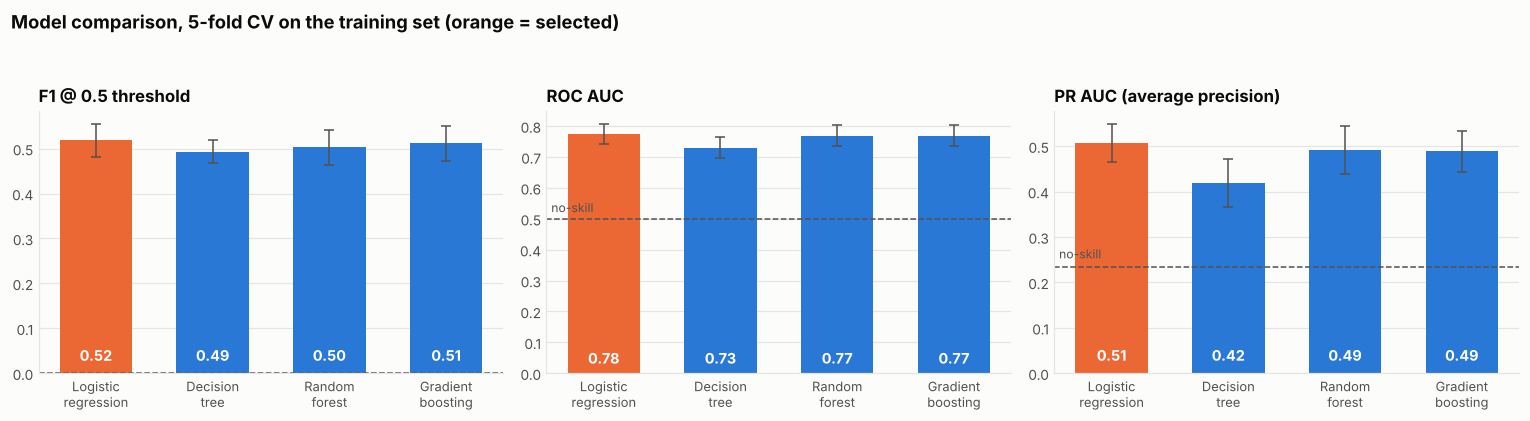

In [ ]:
best_name = cv_mean.loc[CONTENDERS, "pr_auc"].idxmax()
print(f"Selected model (highest CV PR-AUC among the four contenders): {best_name}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (metric, title) in zip(axes, [("f1", "F1 @ 0.5 threshold"), ("roc_auc", "ROC AUC"), ("pr_auc", "PR AUC (average precision)")]):
    vals = cv_mean.loc[CONTENDERS, metric]
    errs = cv_std.loc[CONTENDERS, metric]
    cols = [ORANGE if n == best_name else BLUE for n in CONTENDERS]
    ax.bar(range(4), vals, yerr=errs, color=cols, width=0.62, error_kw={"ecolor": INK2, "lw": 1, "capsize": 3})
    for i, v in enumerate(vals):
        ax.text(i, 0.02, f"{v:.2f}", ha="center", va="bottom", color="white", fontsize=9.5, fontweight="bold")
    ax.set_xticks(range(4))
    ax.set_xticklabels([n.replace(" ", "\n") for n in CONTENDERS], fontsize=8.5)
    base = {"f1": cv_mean.loc["Majority-class dummy", "f1"], "roc_auc": 0.5, "pr_auc": y_train.mean()}[metric]
    ax.axhline(base, color=INK2, lw=1, ls="--")
    if metric != "f1":   # the F1 baseline sits on the axis; the title/caption covers it
        ax.text(-0.45, base + 0.012, "no-skill", fontsize=8, color=INK2, ha="left", va="bottom")
    ax.set_title(title)
    style(ax)
fig.suptitle("Model comparison, 5-fold CV on the training set (orange = selected)", x=0.01, ha="left", fontweight="bold", fontsize=12, y=1.05)
fig.tight_layout()
save(fig, "03_model_comparison.png")

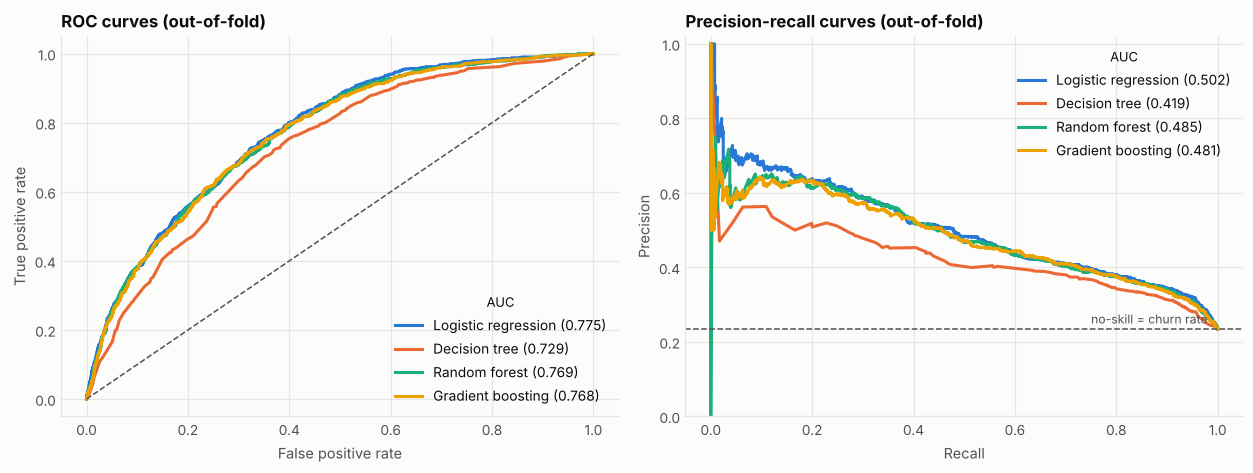

In [ ]:
series_colors = dict(zip(CONTENDERS, [BLUE, ORANGE, AQUA, YELLOW]))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for name in CONTENDERS:
    fpr, tpr, _ = roc_curve(y_train, oof[name])
    axes[0].plot(fpr, tpr, color=series_colors[name], lw=2, label=f"{name} ({roc_auc_score(y_train, oof[name]):.3f})")
    pr, rc, _ = precision_recall_curve(y_train, oof[name])
    axes[1].plot(rc, pr, color=series_colors[name], lw=2, label=f"{name} ({average_precision_score(y_train, oof[name]):.3f})")
axes[0].plot([0, 1], [0, 1], color=INK2, lw=1, ls="--")
axes[1].axhline(y_train.mean(), color=INK2, lw=1, ls="--")
axes[1].text(0.98, y_train.mean() + 0.015, "no-skill = churn rate", ha="right", fontsize=8, color=INK2)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (out-of-fold)")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves (out-of-fold)", ylim=(0, 1.02))
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", title="AUC", title_fontsize=8.5)
    style(ax, "both")
fig.tight_layout()
save(fig, "04_roc_pr_curves.png")

### Confusion matrices at the default 0.5 threshold (out-of-fold, training set)
Rows are the true class, columns the prediction; each cell shows the count and the share of that true class.

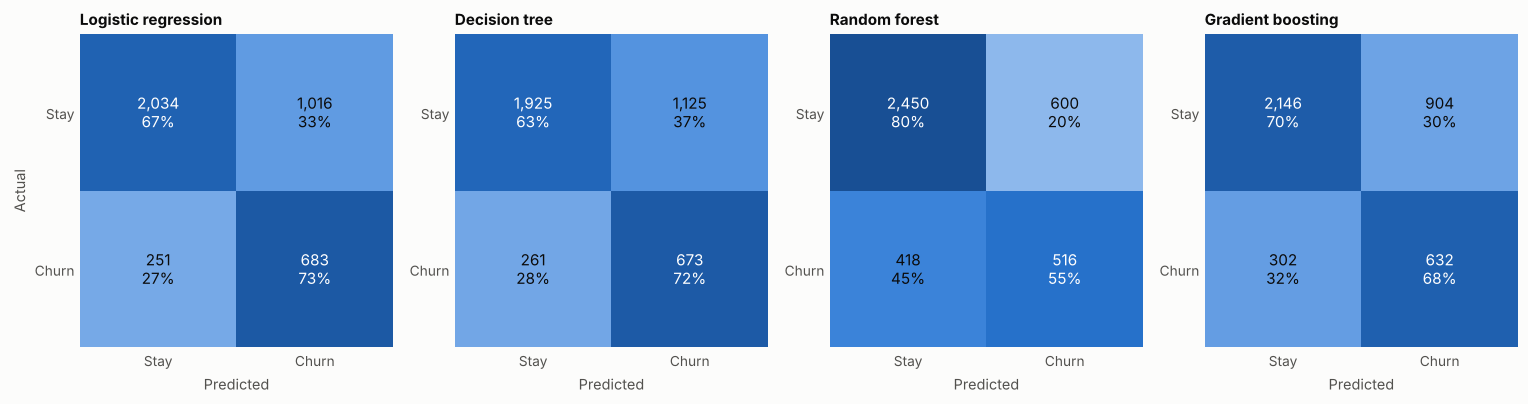

In [ ]:
def draw_cm(ax, y_true, pred, title):
    cm = confusion_matrix(y_true, pred)
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap=BLUE_CMAP, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n{share[i, j]:.0%}", ha="center", va="center", fontsize=10,
                    color="white" if share[i, j] > 0.5 else INK)
    ax.set_xticks([0, 1], ["Stay", "Churn"])
    ax.set_yticks([0, 1], ["Stay", "Churn"])
    ax.set_xlabel("Predicted")
    ax.set_title(title, fontsize=10)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)


fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, name in zip(axes, CONTENDERS):
    draw_cm(ax, y_train, (oof[name] >= 0.5).astype(int), name)
axes[0].set_ylabel("Actual")
fig.tight_layout()
save(fig, "05_confusion_matrices_cv.png")

## 4. Evaluation

### 4a. Threshold tuning (on out-of-fold training predictions)
0.5 is an arbitrary cut-off. Two operating points are chosen **without touching the test set**:
* **F1-optimal**: the best balance of precision and recall.
* **Cost-optimal**: assumes a missed churner costs 5x a wasted retention offer (`FN_COST = 5`, `FP_COST = 1`). These costs are an **assumption**; replace them with real figures from the retention team.

F1-optimal threshold: 0.49 | cost-optimal threshold: 0.32 (FN:FP cost = 5:1)


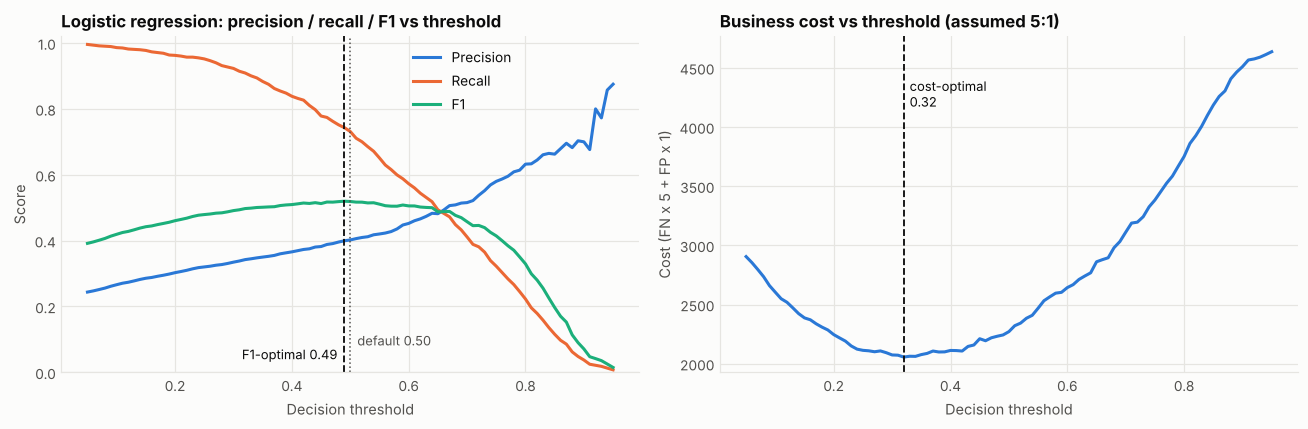

In [ ]:
FN_COST, FP_COST = 5.0, 1.0
thr_grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
p_oof = oof[best_name]
rows = []
for t in thr_grid:
    pred = (p_oof >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    rows.append({"threshold": t, "precision": precision_score(y_train, pred, zero_division=0),
                 "recall": recall_score(y_train, pred), "f1": f1_score(y_train, pred), "cost": FN_COST * fn + FP_COST * fp})
sweep = pd.DataFrame(rows)
THR_F1 = float(sweep.loc[sweep.f1.idxmax(), "threshold"])
THR_COST = float(sweep.loc[sweep.cost.idxmin(), "threshold"])
print(f"F1-optimal threshold: {THR_F1:.2f} | cost-optimal threshold: {THR_COST:.2f} (FN:FP cost = {FN_COST:.0f}:{FP_COST:.0f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
for col, color, label in [("precision", BLUE, "Precision"), ("recall", ORANGE, "Recall"), ("f1", AQUA, "F1")]:
    ax.plot(sweep.threshold, sweep[col], color=color, lw=2, label=label)
ax.axvline(0.5, color=INK2, lw=1, ls=":")
ax.axvline(THR_F1, color=INK, lw=1.2, ls="--")
ax.text(THR_F1 - 0.012, 0.04, f"F1-optimal {THR_F1:.2f}", fontsize=8.5, ha="right")
ax.text(0.512, 0.12, "default 0.50", fontsize=8.5, color=INK2, va="top")
ax.set(xlabel="Decision threshold", ylabel="Score", title=f"{best_name}: precision / recall / F1 vs threshold", ylim=(0, 1.02))
ax.legend(loc="upper right", bbox_to_anchor=(0.80, 1.0))
style(ax, "both")
ax = axes[1]
ax.plot(sweep.threshold, sweep.cost, color=BLUE, lw=2)
ax.axvline(THR_COST, color=INK, lw=1.2, ls="--")
ax.text(THR_COST + 0.01, sweep.cost.max() * 0.9, f"cost-optimal\n{THR_COST:.2f}", fontsize=8.5)
ax.set(xlabel="Decision threshold", ylabel=f"Cost (FN x {FN_COST:.0f} + FP x {FP_COST:.0f})", title="Business cost vs threshold (assumed 5:1)")
style(ax, "both")
fig.tight_layout()
save(fig, "06_threshold_tuning.png")

### 4b. Final evaluation on the held-out test set
The selected pipeline is refit on the **full training set** and scored once on the test set at three thresholds.

In [ ]:
final_pipe = clone(make_pipe(*candidates[best_name])).fit(X_train, y_train)
p_test = final_pipe.predict_proba(X_test)[:, 1]


def test_report(thr):
    pred = (p_test >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"threshold": thr, "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "flagged %": pred.mean() * 100, "cost": FN_COST * fn + FP_COST * fp}


test_tbl = pd.DataFrame({"default 0.50": test_report(0.5), f"F1-optimal {THR_F1:.2f}": test_report(THR_F1),
                         f"cost-optimal {THR_COST:.2f}": test_report(THR_COST)}).T
print(f"Test set: ROC AUC = {roc_auc_score(y_test, p_test):.3f} | PR AUC = {average_precision_score(y_test, p_test):.3f} "
      f"(no-skill PR AUC = {y_test.mean():.3f})")
test_tbl.round(3)

Test set: ROC AUC = 0.766 | PR AUC = 0.479 (no-skill PR AUC = 0.235)


,threshold,precision,recall,f1,TP,FP,FN,TN,flagged %,cost
default 0.50,0.50,0.402,0.709,0.513,166.0,247.0,68.0,516.0,41.424,587.0
F1-optimal 0.49,0.49,0.399,0.718,0.513,168.0,253.0,66.0,510.0,42.227,583.0
cost-optimal 0.32,0.32,0.332,0.889,0.484,208.0,418.0,26.0,345.0,62.788,548.0


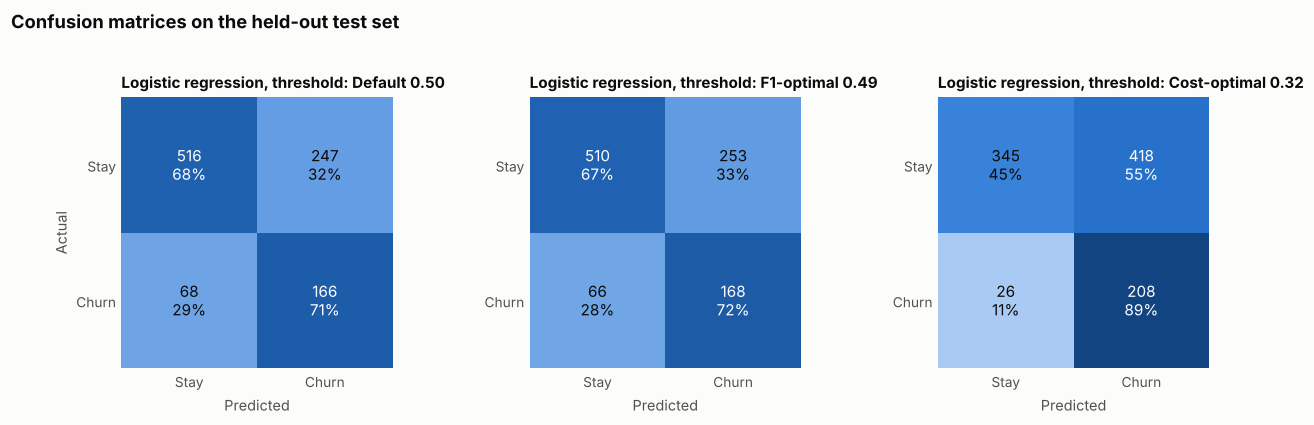

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6))
for ax, (label, thr) in zip(axes, [("Default 0.50", 0.5), (f"F1-optimal {THR_F1:.2f}", THR_F1), (f"Cost-optimal {THR_COST:.2f}", THR_COST)]):
    draw_cm(ax, y_test, (p_test >= thr).astype(int), f"{best_name}, threshold: {label}")
axes[0].set_ylabel("Actual")
fig.suptitle("Confusion matrices on the held-out test set", x=0.01, ha="left", fontweight="bold", fontsize=12, y=1.04)
fig.tight_layout()
save(fig, "07_confusion_matrices_test.png")

In [ ]:
# How certain are the test numbers? Bootstrap the test set 1,000 times.
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
boot = []
for _ in range(1000):
    b = rng.integers(0, len(yt), len(yt))
    pb = (p_test[b] >= THR_F1).astype(int)
    boot.append((precision_score(yt[b], pb, zero_division=0), recall_score(yt[b], pb), f1_score(yt[b], pb),
                 roc_auc_score(yt[b], p_test[b]), average_precision_score(yt[b], p_test[b])))
boot = pd.DataFrame(boot, columns=["precision", "recall", "f1", "roc_auc", "pr_auc"])
ci = boot.quantile([0.025, 0.975]).T.rename(columns={0.025: "ci_low", 0.975: "ci_high"})
ci["estimate"] = [test_tbl.iloc[1]["precision"], test_tbl.iloc[1]["recall"], test_tbl.iloc[1]["f1"],
                  roc_auc_score(y_test, p_test), average_precision_score(y_test, p_test)]
ci = ci[["estimate", "ci_low", "ci_high"]]
print(f"95% bootstrap intervals on the test set (n = {len(yt)}, F1-optimal threshold {THR_F1:.2f})")
ci.round(3)

95% bootstrap intervals on the test set (n = 997, F1-optimal threshold 0.49)


,estimate,ci_low,ci_high
precision,0.399,0.356,0.446
recall,0.718,0.664,0.776
f1,0.513,0.468,0.559
roc_auc,0.766,0.733,0.801
pr_auc,0.479,0.423,0.547


### 4c. Integrity checks: class imbalance and data leakage

In [ ]:
# --- Class imbalance: does weighting matter, and is accuracy a trap?
imb = cv_mean.loc[["Majority-class dummy", "Logistic (no class weights)", "Logistic regression"],
                  ["accuracy", "precision", "recall", "f1", "pr_auc"]].round(3)
print(f"Churn share: train {y_train.mean():.1%}, test {y_test.mean():.1%} (about 1 churner per {(1 - y_train.mean()) / y_train.mean():.1f} stayers)\n")
print("CV @ 0.5 threshold. Note the dummy's high accuracy with zero recall, and how weighting trades precision for recall:")
imb

Churn share: train 23.4%, test 23.5% (about 1 churner per 3.3 stayers)

CV @ 0.5 threshold. Note the dummy's high accuracy with zero recall, and how weighting trades precision for recall:


,accuracy,precision,recall,f1,pr_auc
Majority-class dummy,0.766,0.000,0.000,0.000,0.234
Logistic (no class weights),0.787,0.595,0.291,0.391,0.508
Logistic regression,0.682,0.402,0.731,0.519,0.507


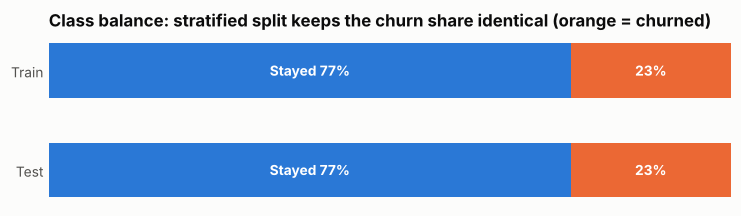

In [ ]:
fig, ax = plt.subplots(figsize=(8, 2.0))
for i, (label, yy) in enumerate([("Train", y_train), ("Test", y_test)]):
    ax.barh(i, 1 - yy.mean(), color=BLUE, height=0.55)
    ax.barh(i, yy.mean(), left=1 - yy.mean(), color=ORANGE, height=0.55)
    ax.text((1 - yy.mean()) / 2, i, f"Stayed {1 - yy.mean():.0%}", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
    ax.text(1 - yy.mean() / 2, i, f"{yy.mean():.0%}", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
ax.set_yticks([0, 1], ["Train", "Test"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xticks([])
ax.set_title("Class balance: stratified split keeps the churn share identical (orange = churned)")
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
save(fig, "08_class_balance.png")

In [ ]:
# --- Leakage audit 1: columns that only exist after churn
lk = leak.copy()
lk["reason_recorded"] = lk.cancellation_reason.notna()
print("Raw `cancellation_reason` recorded vs actual churn (rows):")
print(pd.crosstab(lk.reason_recorded, lk.churned, rownames=["reason recorded"], colnames=["churned"]))
print(f"\nAUC of the single flag 'reason is recorded' = {roc_auc_score(lk.churned, lk.reason_recorded):.3f}  <- a perfect score is the red flag")

leaky_X = X_train.assign(reason_recorded=leak.loc[X_train.index, "cancellation_reason"].notna().astype(float))
leaky_pipe = Pipeline([("prep", ColumnTransformer([("num", SimpleImputer(strategy="median"), ["reason_recorded"])])),
                       ("clf", LogisticRegression())])
leaky_p = np.zeros(len(y_train))
for tr, va in folds:
    leaky_p[va] = clone(leaky_pipe).fit(leaky_X.iloc[tr], y_train.iloc[tr]).predict_proba(leaky_X.iloc[va])[:, 1]
print(f"Cross-validated AUC if that one leaky column were kept: {roc_auc_score(y_train, leaky_p):.3f} "
      f"vs honest {best_name}: {roc_auc_score(y_train, oof[best_name]):.3f}")

Raw `cancellation_reason` recorded vs actual churn (rows):
churned             0     1
reason recorded            
False            3813     0
True                0  1168

AUC of the single flag 'reason is recorded' = 1.000  <- a perfect score is the red flag
Cross-validated AUC if that one leaky column were kept: 1.000 vs honest Logistic regression: 0.775


In [ ]:
# --- Leakage audit 2: univariate screen of the real features (a single feature with AUC > 0.85 deserves suspicion)
uni = []
for c in NUM:
    v = X_train[c].fillna(X_train[c].median())
    a = roc_auc_score(y_train, v)
    uni.append({"feature": c, "auc": a, "strength (|AUC-0.5|+0.5)": max(a, 1 - a), "direction": "higher -> churn" if a > 0.5 else "higher -> stay"})
uni = pd.DataFrame(uni).sort_values("strength (|AUC-0.5|+0.5)", ascending=False).reset_index(drop=True)
print(f"Strongest single feature: {uni.iloc[0].feature} at {uni.iloc[0]['strength (|AUC-0.5|+0.5)']:.3f} -> nothing suspiciously perfect")
uni.head(8).round(3)

Strongest single feature: tenure_months at 0.687 -> nothing suspiciously perfect


,feature,auc,strength (|AUC-0.5|+0.5),direction
0,tenure_months,0.313,0.687,higher -> stay
1,logins_trend_pct,0.346,0.654,higher -> stay
2,logins_drop_ratio,0.347,0.653,higher -> stay
3,logins_slope,0.354,0.646,higher -> stay
4,friction_score,0.609,0.609,higher -> churn
5,minutes_per_dollar,0.396,0.604,higher -> stay
6,logins_cv,0.601,0.601,higher -> churn
7,support_tickets_6m,0.597,0.597,higher -> churn


In [ ]:
# --- Leakage audit 3: label-shuffle sanity check (a leak-free pipeline must score ~0.5 on shuffled labels)
rng = np.random.default_rng(SEED)
y_shuf = pd.Series(rng.permutation(y_train.to_numpy()), index=y_train.index)
p_shuf = np.zeros(len(y_train))
for tr, va in folds:
    p_shuf[va] = clone(make_pipe(*candidates[best_name])).fit(X_train.iloc[tr], y_shuf.iloc[tr]).predict_proba(X_train.iloc[va])[:, 1]
shuf_auc = roc_auc_score(y_shuf, p_shuf)

checks = pd.DataFrame([
    ["Post-churn columns removed", "cancellation_reason, account_closed_date dropped before modelling", "PASS"],
    ["No customer in both train and test", f"{len(set(X_train.index) & set(X_test.index))} shared customer IDs", "PASS"],
    ["No duplicated customers", "customer_id is unique in the modelling table", "PASS" if model_df.index.is_unique else "FAIL"],
    ["Learned preprocessing is fit on training folds only", "imputer, winsoriser, scaler, encoder all live inside the Pipeline", "PASS"],
    ["Features use only the pre-snapshot window", "usage / tickets / late payments are 6-month history ending at the snapshot date", "PASS (by construction; see limitations)"],
    ["Threshold chosen without the test set", "tuned on out-of-fold training predictions", "PASS"],
    ["No implausibly strong single feature", f"max univariate AUC {uni.iloc[0]['strength (|AUC-0.5|+0.5)']:.3f}", "PASS" if uni.iloc[0]["strength (|AUC-0.5|+0.5)"] < 0.85 else "REVIEW"],
    ["Label-shuffle sanity check", f"CV AUC on shuffled labels = {shuf_auc:.3f} (expect ~0.50)", "PASS" if abs(shuf_auc - 0.5) < 0.05 else "REVIEW"],
], columns=["check", "evidence", "result"])
checks

,check,evidence,result
0,Post-churn columns removed,"cancellation_reason, account_closed_date dropp...",PASS
1,No customer in both train and test,0 shared customer IDs,PASS
2,No duplicated customers,customer_id is unique in the modelling table,PASS
3,Learned preprocessing is fit on training folds...,"imputer, winsoriser, scaler, encoder all live ...",PASS
4,Features use only the pre-snapshot window,usage / tickets / late payments are 6-month hi...,PASS (by construction; see limitations)
5,Threshold chosen without the test set,tuned on out-of-fold training predictions,PASS
6,No implausibly strong single feature,max univariate AUC 0.687,PASS
7,Label-shuffle sanity check,CV AUC on shuffled labels = 0.500 (expect ~0.50),PASS


## 5. What drives the predictions?

Three complementary views:
* **Permutation importance** (selected model, test set): how much does PR-AUC drop when a feature's observed values are shuffled? Model-agnostic, one bar per original feature. A custom version is used because sklearn's also shuffles NaN positions, which flips the pipeline's missing-indicator columns and credits missingness to the feature.
* **Logistic-regression coefficients**: the *direction* and relative size of each effect (per 1 standard deviation).
* **Partial dependence**: the shape of the effect for the top numeric features.

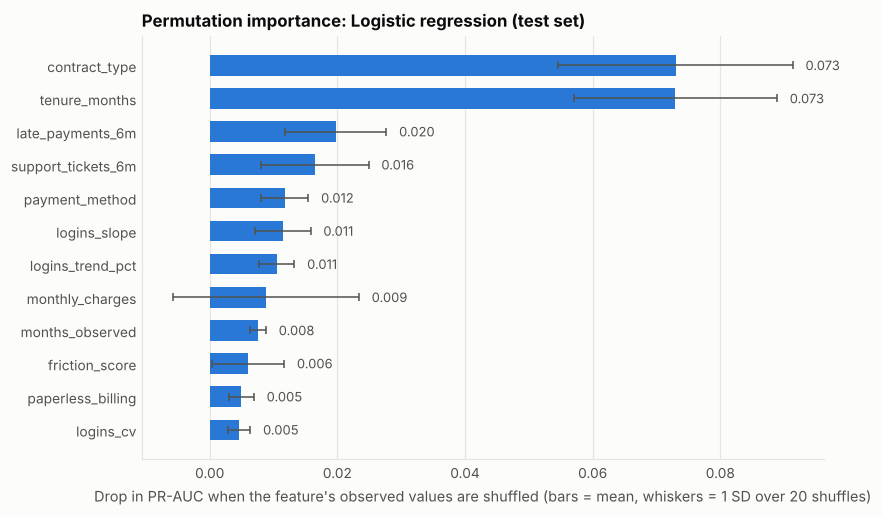

In [ ]:
def perm_importance(pipe, X, y, n_repeats=20, seed=SEED):
    """Permutation importance that shuffles only the OBSERVED values of a column and leaves NaNs where they are.

    sklearn's version also moves the NaNs around. Because the pipeline adds missing-indicator columns, that
    silently flips the indicators and credits the *missingness pattern* to the feature (it ranked a feature
    with a ~0 coefficient 3rd in an earlier run of this notebook).
    """
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, pipe.predict_proba(X)[:, 1])
    out = {}
    for col in X.columns:
        obs = X[col].notna().to_numpy()
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            vals = Xp.loc[obs, col].to_numpy()
            Xp.loc[obs, col] = rng.permutation(vals)
            drops.append(base - average_precision_score(y, pipe.predict_proba(Xp)[:, 1]))
        out[col] = (np.mean(drops), np.std(drops))
    return pd.DataFrame(out, index=["importance", "std"]).T.rename_axis("feature").reset_index()


imp = perm_importance(final_pipe, X_test, y_test).sort_values("importance", ascending=False).reset_index(drop=True)
imp.to_csv(REP / "permutation_importance.csv", index=False)

top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.feature, top.importance, xerr=top["std"], color=BLUE, height=0.62, error_kw={"ecolor": INK2, "lw": 1, "capsize": 2.5})
for y_, (v, s_) in enumerate(zip(top.importance, top["std"])):
    ax.text(max(v + s_, 0) + 0.002, y_, f"{v:.3f}", va="center", fontsize=8.5, color=INK2)
ax.set_xlabel("Drop in PR-AUC when the feature's observed values are shuffled (bars = mean, whiskers = 1 SD over 20 shuffles)")
ax.set_title(f"Permutation importance: {best_name} (test set)")
style(ax, "x")
save(fig, "09_permutation_importance.png")

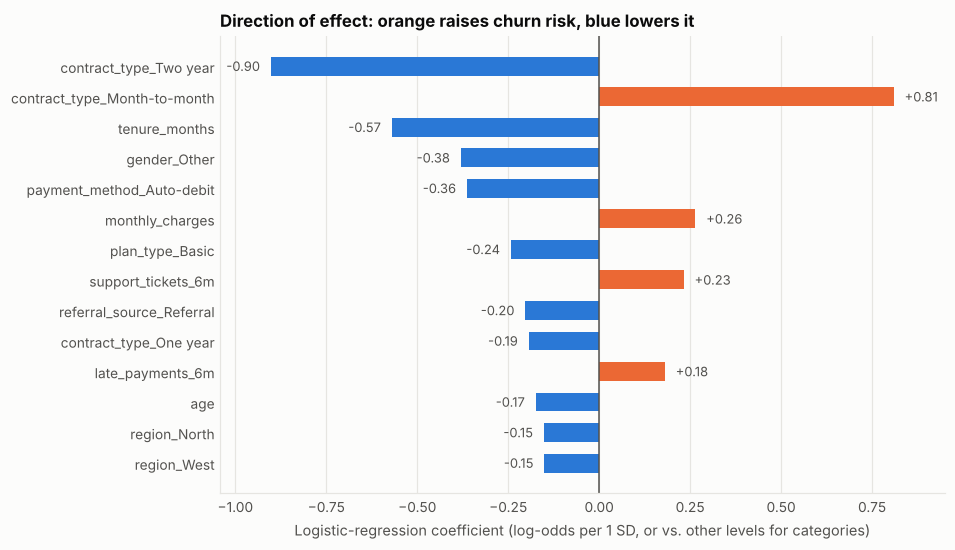

In [ ]:
lr_pipe = clone(make_pipe(*candidates["Logistic regression"])).fit(X_train, y_train)
names = lr_pipe[:-1].get_feature_names_out()
names = np.array([n.split("__", 1)[1] for n in names])
coef = pd.Series(lr_pipe[-1].coef_[0], index=names)
coef = coef[~coef.index.str.startswith("missingindicator_")]
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(14).iloc[::-1]

fig, ax = plt.subplots(figsize=(8.5, 5.4))
ax.barh(top.index, top.values, color=np.where(top.values > 0, ORANGE, BLUE), height=0.62)
ax.axvline(0, color=INK2, lw=1)
for y_, v in enumerate(top.values):
    ax.text(v + (0.03 if v > 0 else -0.03), y_, f"{v:+.2f}", va="center", ha="left" if v > 0 else "right", fontsize=8.5, color=INK2)
ax.set_xlim(top.values.min() - 0.14, top.values.max() + 0.14)
ax.set_xlabel("Logistic-regression coefficient (log-odds per 1 SD, or vs. other levels for categories)")
ax.set_title("Direction of effect: orange raises churn risk, blue lowers it")
style(ax, "x")
save(fig, "10_lr_coefficients.png")

Top numeric drivers: ['tenure_months', 'late_payments_6m', 'support_tickets_6m', 'logins_slope']


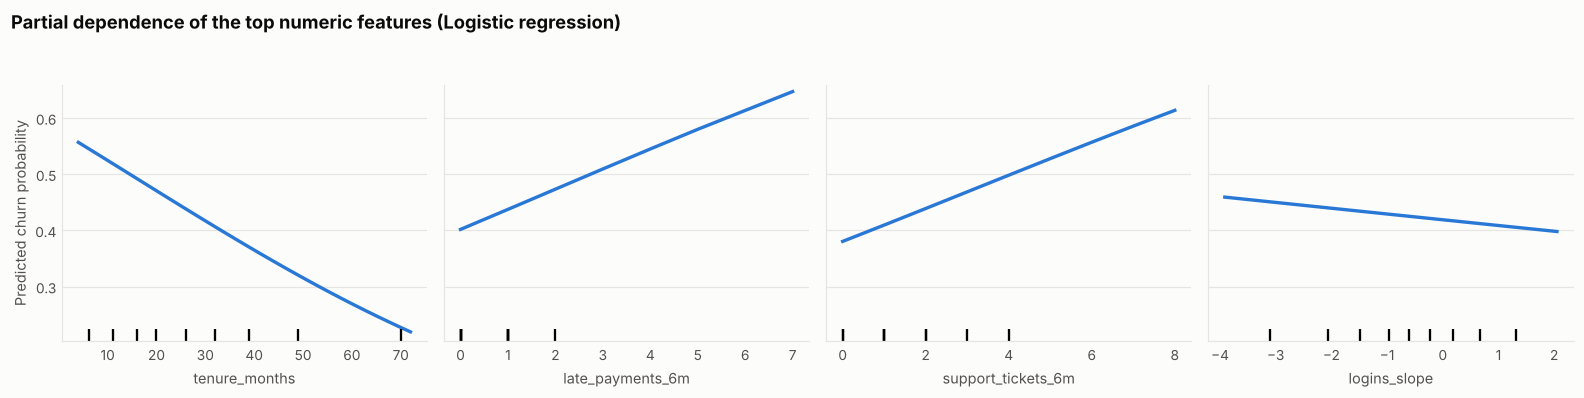

In [ ]:
top_num = [f for f in imp.feature if f in NUM][:4]
fig, axes = plt.subplots(1, 4, figsize=(14.5, 3.4), sharey=True)
PartialDependenceDisplay.from_estimator(final_pipe, X_test, top_num, kind="average", ax=axes,
                                        line_kw={"color": BLUE, "lw": 2.2}, grid_resolution=30)
for ax in axes:
    style(ax)
    ax.set_ylabel("")
axes[0].set_ylabel("Predicted churn probability")
fig.suptitle(f"Partial dependence of the top numeric features ({best_name})", x=0.01, ha="left", fontweight="bold", fontsize=12, y=1.05)
fig.tight_layout()
save(fig, "11_partial_dependence.png")
print("Top numeric drivers:", top_num)

In [ ]:
# Human-readable rules from a shallow decision tree (global surrogate-style view; not the selected model)
rule_pipe = make_pipe(DecisionTreeClassifier(max_depth=3, min_samples_leaf=60, class_weight="balanced", random_state=SEED)).fit(X_train, y_train)
rule_names = [n.split("__", 1)[1] for n in rule_pipe[:-1].get_feature_names_out()]
print(export_text(rule_pipe[-1], feature_names=rule_names, decimals=2))

|--- contract_type_Month-to-month <= 0.50
|   |--- tenure_months <= 36.50
|   |   |--- late_payments_6m <= 0.50
|   |   |   |--- class: 0
|   |   |--- late_payments_6m >  0.50
|   |   |   |--- class: 0
|   |--- tenure_months >  36.50
|   |   |--- monthly_charges <= 41.82
|   |   |   |--- class: 0
|   |   |--- monthly_charges >  41.82
|   |   |   |--- class: 0
|--- contract_type_Month-to-month >  0.50
|   |--- logins_trend_pct <= -0.05
|   |   |--- friction_score <= 1.50
|   |   |   |--- class: 1
|   |   |--- friction_score >  1.50
|   |   |   |--- class: 1
|   |--- logins_trend_pct >  -0.05
|   |   |--- monthly_charges <= 51.52
|   |   |   |--- class: 0
|   |   |--- monthly_charges >  51.52
|   |   |   |--- class: 1



## 6. Error analysis
Where does the model go wrong at the chosen (F1-optimal) threshold, on the test set?

outcome
TP    168
FP    253
FN     66
TN    510


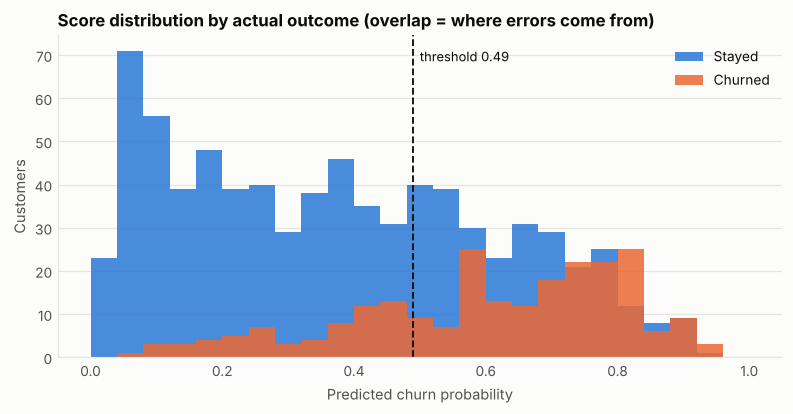

In [ ]:
res = X_test.copy()
res["actual"] = y_test
res["proba"] = p_test
res["pred"] = (p_test >= THR_F1).astype(int)
res["outcome"] = np.select([(res.actual == 1) & (res.pred == 1), (res.actual == 0) & (res.pred == 1),
                            (res.actual == 1) & (res.pred == 0)], ["TP", "FP", "FN"], "TN")
print(res.outcome.value_counts().reindex(["TP", "FP", "FN", "TN"]).to_string())

fig, ax = plt.subplots(figsize=(8.5, 3.8))
bins = np.linspace(0, 1, 26)
ax.hist(res.proba[res.actual == 0], bins=bins, color=BLUE, alpha=0.85, label="Stayed")
ax.hist(res.proba[res.actual == 1], bins=bins, color=ORANGE, alpha=0.85, label="Churned")
ax.axvline(THR_F1, color=INK, lw=1.2, ls="--")
ax.text(THR_F1 + 0.01, ax.get_ylim()[1] * 0.92, f"threshold {THR_F1:.2f}", fontsize=8.5)
ax.set(xlabel="Predicted churn probability", ylabel="Customers", title="Score distribution by actual outcome (overlap = where errors come from)")
ax.legend()
style(ax)
save(fig, "12_score_distribution.png")

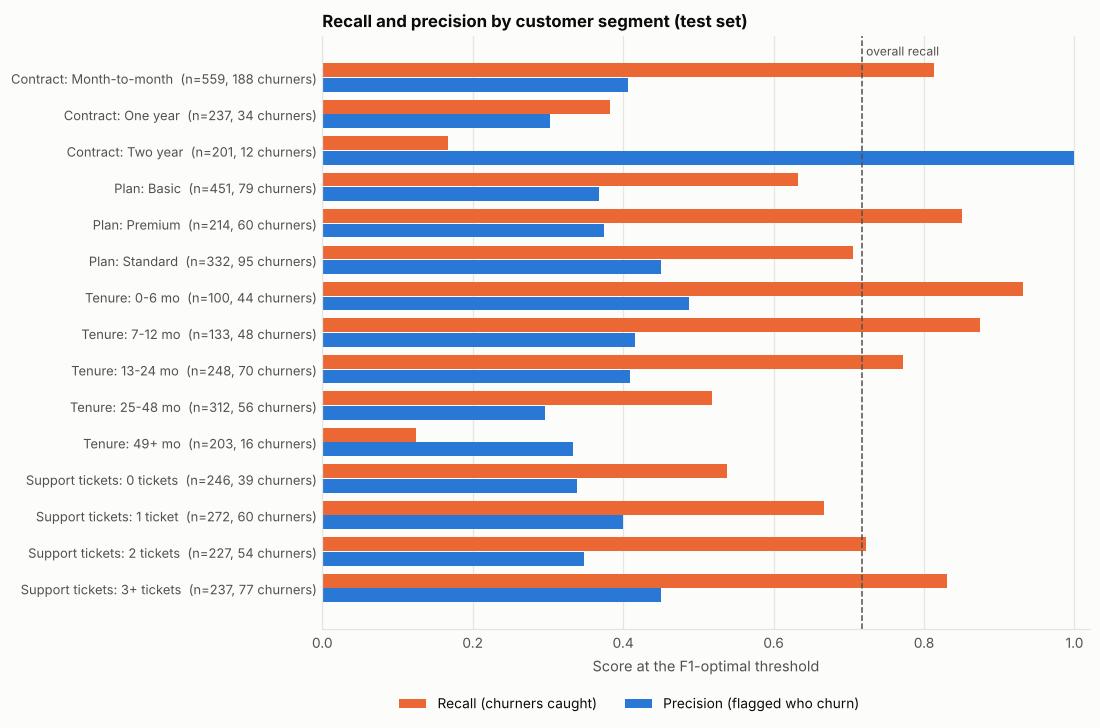

,segment,n,churners,recall,precision,churn_rate
0,Contract: Month-to-month,559,188,0.814,0.407,0.336
1,Contract: One year,237,34,0.382,0.302,0.143
2,Contract: Two year,201,12,0.167,1.000,0.060
3,Plan: Basic,451,79,0.633,0.368,0.175
4,Plan: Premium,214,60,0.850,0.375,0.280
5,Plan: Standard,332,95,0.705,0.450,0.286
6,Tenure: 0-6 mo,100,44,0.932,0.488,0.440
7,Tenure: 7-12 mo,133,48,0.875,0.416,0.361
8,Tenure: 13-24 mo,248,70,0.771,0.409,0.282
9,Tenure: 25-48 mo,312,56,0.518,0.296,0.179


In [ ]:
res["tenure_band"] = pd.cut(res.tenure_months, [0, 6, 12, 24, 48, 200], labels=["0-6 mo", "7-12 mo", "13-24 mo", "25-48 mo", "49+ mo"])
res["tickets_band"] = pd.cut(res.support_tickets_6m, [-1, 0, 1, 2, 100], labels=["0 tickets", "1 ticket", "2 tickets", "3+ tickets"])
segments = [("contract_type", "Contract"), ("plan_type", "Plan"), ("tenure_band", "Tenure"), ("tickets_band", "Support tickets")]
seg_rows = []
for col, label in segments:
    for lvl, d in res.groupby(col, observed=True):
        pos = d[d.actual == 1]
        flagged = d[d.pred == 1]
        seg_rows.append({"segment": f"{label}: {lvl}", "n": len(d), "churners": len(pos),
                         "recall": (pos.pred == 1).mean() if len(pos) else np.nan,
                         "precision": (flagged.actual == 1).mean() if len(flagged) else np.nan,
                         "churn_rate": d.actual.mean()})
seg = pd.DataFrame(seg_rows)
seg.to_csv(REP / "error_by_segment.csv", index=False)

plot = seg.iloc[::-1]
yy = np.arange(len(plot))
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(yy + 0.2, plot.recall, height=0.38, color=ORANGE, label="Recall (churners caught)")
ax.barh(yy - 0.2, plot.precision, height=0.38, color=BLUE, label="Precision (flagged who churn)")
ax.set_yticks(yy, [f"{s}  (n={n}, {c} churners)" for s, n, c in zip(plot.segment, plot.n, plot.churners)], fontsize=8.5)
ax.axvline(res[res.actual == 1].pred.mean(), color=INK2, lw=1, ls="--")
ax.text(res[res.actual == 1].pred.mean() + 0.005, len(plot) - 0.4, "overall recall", fontsize=8, color=INK2)
ax.set(xlim=(0, 1.02), xlabel="Score at the F1-optimal threshold", title="Recall and precision by customer segment (test set)")
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.09), ncol=2)
style(ax, "x")
save(fig, "13_error_by_segment.png")
seg.round(3)

In [ ]:
# What do the missed churners (FN) look like compared with the caught ones (TP)?  Standardised mean difference.
sd = X_train[NUM].std()
smd = ((res[res.outcome == "FN"][NUM].mean() - res[res.outcome == "TP"][NUM].mean()) / sd).rename("FN minus TP (in SDs)")
smd = smd.reindex(smd.abs().sort_values(ascending=False).index).head(8)
fp_vs_tn = ((res[res.outcome == "FP"][NUM].mean() - res[res.outcome == "TN"][NUM].mean()) / sd).rename("FP minus TN (in SDs)")
fp_vs_tn = fp_vs_tn.reindex(fp_vs_tn.abs().sort_values(ascending=False).index).head(8)
print("Missed churners (FN) vs caught churners (TP): FNs look like 'normal' customers on these features")
print(smd.round(2).to_string())
print("\nFalse alarms (FP) vs correctly-cleared stayers (TN): FPs look like churners on these features")
print(fp_vs_tn.round(2).to_string())

Missed churners (FN) vs caught churners (TP): FNs look like 'normal' customers on these features
logins_trend_pct      1.02
logins_cv            -0.93
logins_slope          0.88
tenure_months         0.83
logins_drop_ratio     0.82
friction_score       -0.67
is_new_customer      -0.65
support_tickets_6m   -0.55

False alarms (FP) vs correctly-cleared stayers (TN): FPs look like churners on these features
tenure_months        -1.05
logins_trend_pct     -0.77
logins_drop_ratio    -0.75
logins_slope         -0.74
support_tickets_6m    0.49
friction_score        0.48
is_new_customer       0.47
minutes_per_dollar   -0.43


## 7. Summary

In [ ]:
r = test_tbl.iloc[1]
top5 = ", ".join(imp.feature.head(5))
summary = {
    "selected_model": best_name,
    "threshold_f1_optimal": THR_F1,
    "threshold_cost_optimal": THR_COST,
    "test_roc_auc": float(roc_auc_score(y_test, p_test)),
    "test_pr_auc": float(average_precision_score(y_test, p_test)),
    "test_precision": float(r.precision), "test_recall": float(r.recall), "test_f1": float(r.f1),
    "test_churn_rate": float(y_test.mean()),
    "ci_f1": [float(ci.loc["f1", "ci_low"]), float(ci.loc["f1", "ci_high"])],
    "top_features": imp.feature.head(8).tolist(),
}
(REP / "test_metrics.json").write_text(json.dumps(summary, indent=2))
test_tbl.round(4).to_csv(REP / "test_metrics_by_threshold.csv")

print(f"Selected model : {best_name}")
print(f"Test ROC AUC   : {summary['test_roc_auc']:.3f}   PR AUC {summary['test_pr_auc']:.3f} (no-skill {y_test.mean():.3f})")
print(f"At threshold {THR_F1:.2f}: precision {r.precision:.2f} | recall {r.recall:.2f} | F1 {r.f1:.2f}  "
      f"(95% CI for F1: {ci.loc['f1', 'ci_low']:.2f}-{ci.loc['f1', 'ci_high']:.2f})")
print(f"Flags {r['flagged %']:.0f}% of customers and catches {r.recall:.0%} of churners (base churn rate {y_test.mean():.0%})")
print(f"Top drivers    : {top5}")
print("Saved          : reports/cleaning_log.csv, model_comparison_cv.csv, test_metrics.json, permutation_importance.csv, figures/*.png")

Selected model : Logistic regression
Test ROC AUC   : 0.766   PR AUC 0.479 (no-skill 0.235)
At threshold 0.49: precision 0.40 | recall 0.72 | F1 0.51  (95% CI for F1: 0.47-0.56)
Flags 42% of customers and catches 72% of churners (base churn rate 23%)
Top drivers    : contract_type, tenure_months, late_payments_6m, support_tickets_6m, payment_method
Saved          : reports/cleaning_log.csv, model_comparison_cv.csv, test_metrics.json, permutation_importance.csv, figures/*.png
